# Visualization

## 1. Subtyping test

TO ADD

## 2. TME archetypes

### Tensorboard

In [8]:
# After checking results make sure to kill session via lsof -i :6006
# Run this in local terminal: ssh -L 6006:localhost:6006 ubuntu@172.23.142.23

%load_ext tensorboard

In [ ]:
%tensorboard --logdir '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/train_b32_lr2low_svm_s1/' --host 0.0.0.0 --port 6006

### Grid search results

In [1]:
import glob
import os
import pickle

# Base directory path
base_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/'

# Find all .pkl files in subdirectories containing 'tuning'
pkl_files = glob.glob(os.path.join(base_dir, '**', '*tuning*', '*.pkl'), recursive=True)

# Load data from all matched .pkl files
data_list = []
for file in pkl_files:
    with open(file, 'rb') as f:
        data = pickle.load(f)
        data_list.append(data)

print(f"Loaded {len(data_list)} .pkl files")

results = data_list

Loaded 31 .pkl files


In [3]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Prepare lists to store performance metrics (F1 scores, etc.)
file_names = [file.split('/')[-2] for file in pkl_files]
f1_scores_weighted = []
accuracy_scores = []
precision_scores = []
recall_scores = []
confusion_matrices = []

# Loop through the results of each fold
for result in results:
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))  # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)
    
    # Calculate the confusion matrix for the current fold
    cm = confusion_matrix(true_labels, pred_labels)
    confusion_matrices.append(cm)
    
    # Compute accuracy, precision, recall, and F1 scores
    accuracy_scores.append(accuracy_score(true_labels, pred_labels))
    precision_scores.append(precision_score(true_labels, pred_labels, average='weighted'))
    recall_scores.append(recall_score(true_labels, pred_labels, average='weighted'))
    
    # Calculate the weighted F1 score and append it to the list
    weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')
    f1_scores_weighted.append(weighted_f1)

# Visualize performance scores across folds
metrics_df = pd.DataFrame({
    'Name': file_names,
    'Accuracy': accuracy_scores,
    'Precision (weighted)': precision_scores,
    'Recall (weighted)': recall_scores,
    'F1 Score (weighted)': f1_scores_weighted
})

metrics_df.sort_values('F1 Score (weighted)')

,Name,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
5,tuning_b16_lr1_s1,0.6000,0.680442,0.6000,0.604907
6,tuning_b32_lr1_s1,0.6000,0.680442,0.6000,0.604907
4,tuning_b8_lr1_s1,0.6000,0.680442,0.6000,0.604907
0,tuning_b4_lr5vlow_s1,0.6125,0.696489,0.6125,0.620138
22,tuning_b32_lr1_svm_s1,0.6625,0.721071,0.6625,0.670670
20,tuning_b8_lr1_svm_s1,0.6750,0.744650,0.6750,0.681697
21,tuning_b16_lr1_svm_s1,0.6750,0.739286,0.6750,0.682989
19,tuning_b4_lr1_svm_s1,0.6750,0.739286,0.6750,0.682989
3,tuning_b32_lr5vlow_s1,0.8125,0.828566,0.8125,0.815943
2,tuning_b16_lr5vlow_s1,0.8125,0.828566,0.8125,0.815943


### Training results

In [ ]:
# Defaults from summary file

import pandas as pd
import numpy as np
import os 

import matplotlib.pyplot as plt
import seaborn as sns

summary_df = pd.read_csv(os.path.join('/mnt/central_nas/rcc_volume/RCC/HE/CLAM/subtyping_test/results/dry_run_s1/summary.csv'))
summary_df['group'] = 'subtyping'
print(summary_df.head())

## Acurracy
auc_viz = summary_df.melt(id_vars= 'folds', value_vars= ['test_acc', 'val_acc'], var_name= 'type', value_name= 'acc')

sns.set_style('white')
p = sns.boxplot(data=acc_viz, x='type', y='acc', hue='type', palette = 'Set1',showfliers=False)
p = sns.stripplot(data=acc_viz, x='type', y='acc', hue='type', palette = 'Set1', alpha=0.5)
p.set(ylim=(0.5,1))
plt.show()
plt.close()

## AUC
auc_viz = summary_df.melt(id_vars= 'folds', value_vars= ['test_auc', 'val_auc'], var_name= 'type', value_name= 'auc')

sns.set_style('white')
p = sns.boxplot(data=auc_viz, x='type', y='auc', hue='type', palette = 'Set1',showfliers=False)
p = sns.stripplot(data=auc_viz, x='type', y='auc', hue='type', palette = 'Set1', alpha=0.5)
p.set(ylim=(0.5,1))
plt.show()

In [11]:
# Custom reading in of result files 

import glob
import os
import pickle

# Base directory path
base_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/'

# Find all .pkl files in subdirectories containing 'tuning'
pkl_files = glob.glob(os.path.join(base_dir, '**', '*b32_lr1low_svm_val2*','*.pkl'), recursive=True)

# Load data from all matched .pkl files
data_list = []
for file in pkl_files:
    with open(file, 'rb') as f:
        data = pickle.load(f)
        data_list.append(data)

print(f"Loaded {len(data_list)} .pkl files")

results = data_list

Loaded 8 .pkl files


In [12]:
# Baseline accuracies and F1 scores
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay
from collections import Counter

# Collect all true labels
true_labels = []
for result in results:
    for key, value in result.items():
        true_labels.append(value['label'])

true_labels = np.array(true_labels)

# Baseline 1: Most Frequent Class
most_common_class = Counter(true_labels).most_common(1)[0][0]
baseline_pred_mfc = np.full_like(true_labels, most_common_class)
baseline_f1_mfc = f1_score(true_labels, baseline_pred_mfc, average='weighted')
baseline_acc_mfc = accuracy_score(true_labels, baseline_pred_mfc)

# Baseline 2: Random Guessing Based on Class Distribution
class_counts = Counter(true_labels)
class_probs = np.array([class_counts[i] / len(true_labels) for i in range(len(class_counts))])
np.random.seed(42) 
baseline_pred_random = np.random.choice(list(class_counts.keys()), size=len(true_labels), p=class_probs)
baseline_f1_random = f1_score(true_labels, baseline_pred_random, average='weighted')
baseline_acc_random = accuracy_score(true_labels, baseline_pred_random)

print(f"Baseline F1 Score (Most Frequent Class): {baseline_f1_mfc:.4f}")
print(f"Baseline F1 Score (Random Guessing): {baseline_f1_random:.4f}")

Baseline F1 Score (Most Frequent Class): 0.4883
Baseline F1 Score (Random Guessing): 0.3428


In [13]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Prepare lists to store performance metrics (F1 scores, etc.)
file_names = [file.split('/')[-2] for file in pkl_files]
f1_scores_weighted = []
accuracy_scores = []
precision_scores = []
recall_scores = []
confusion_matrices = []

# Loop through the results of each fold
for result in results:
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))  # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)
    
    # Calculate the confusion matrix for the current fold
    cm = confusion_matrix(true_labels, pred_labels)
    confusion_matrices.append(cm)
    
    # Compute accuracy, precision, recall, and F1 scores
    accuracy_scores.append(accuracy_score(true_labels, pred_labels))
    precision_scores.append(precision_score(true_labels, pred_labels, average='weighted'))
    recall_scores.append(recall_score(true_labels, pred_labels, average='weighted'))
    
    # Calculate the weighted F1 score and append it to the list
    weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')
    f1_scores_weighted.append(weighted_f1)

# Visualize performance scores across folds
metrics_df = pd.DataFrame({
    'Name': file_names,
    'Accuracy': accuracy_scores,
    'Precision (weighted)': precision_scores,
    'Recall (weighted)': recall_scores,
    'F1 Score (weighted)': f1_scores_weighted
})

metrics_df.sort_values('F1 Score (weighted)')

,Name,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
1,train_b32_lr1low_svm_val2_s1,0.536585,0.522866,0.536585,0.526544
4,train_b32_lr1low_svm_val2_s1,0.645570,0.633463,0.645570,0.633433
7,train_b32_lr1low_svm_val2_s1,0.641975,0.682983,0.641975,0.650114
6,train_b32_lr1low_svm_val2_s1,0.662338,0.702772,0.662338,0.673168
0,train_b32_lr1low_svm_val2_s1,0.683544,0.739973,0.683544,0.697061
5,train_b32_lr1low_svm_val2_s1,0.700000,0.741126,0.700000,0.714062
3,train_b32_lr1low_svm_val2_s1,0.721519,0.767906,0.721519,0.737554
2,train_b32_lr1low_svm_val2_s1,0.812500,0.829167,0.812500,0.816250


In [14]:
mean_title = f"Mean F1 score (weighted): {metrics_df['F1 Score (weighted)'].mean():.3f} +- {metrics_df['F1 Score (weighted)'].std():.3f}"

print(mean_title)


Mean F1 score (weighted): 0.681 +- 0.084


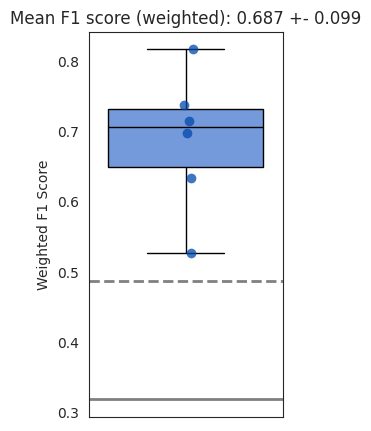

In [7]:
# Plot the boxplot for weighted F1 scores
sns.set_style('white')
plt.figure(figsize=(2.5, 5))
sns.boxplot(data=f1_scores_weighted, color = '#6495ED',
            boxprops={'edgecolor': 'black'},  medianprops={'color': 'black'}, whiskerprops={'color': 'black'}, capprops={'color': 'black'}, 
            showfliers=False)
sns.stripplot(data=f1_scores_weighted, color = "#0047AB", alpha = 0.75, size=7)
plt.axhline(baseline_f1_mfc, color = "grey", linestyle='--', linewidth=2, label='MFC Baseline')
plt.axhline(baseline_f1_random, color='grey', linestyle='-', linewidth=2, label='Random Baseline')
plt.ylabel('Weighted F1 Score')
plt.title(mean_title)
plt.show()

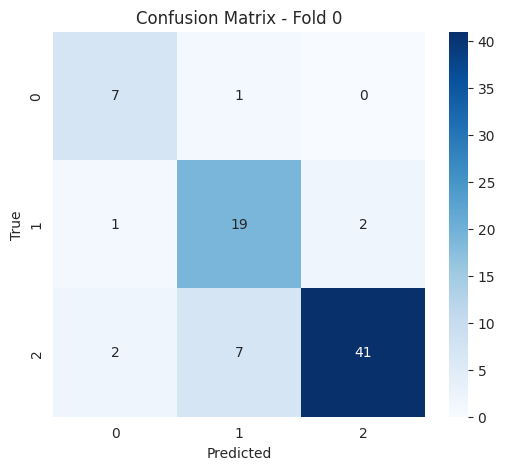

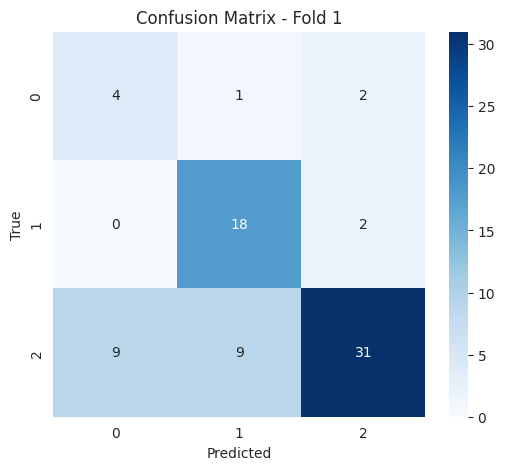

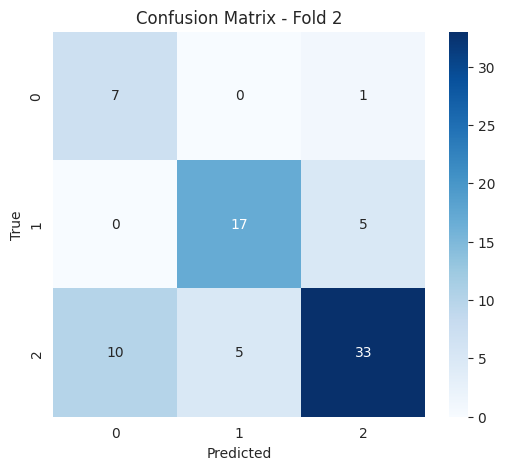

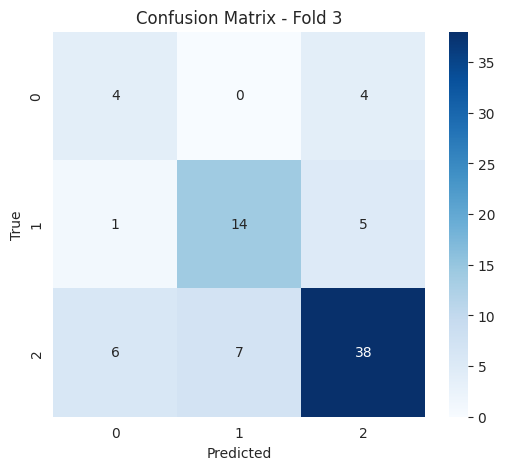

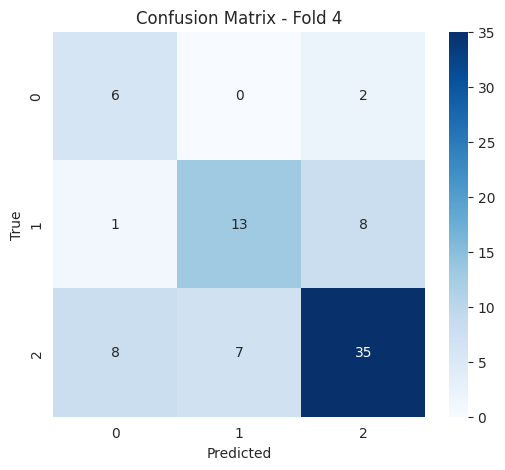

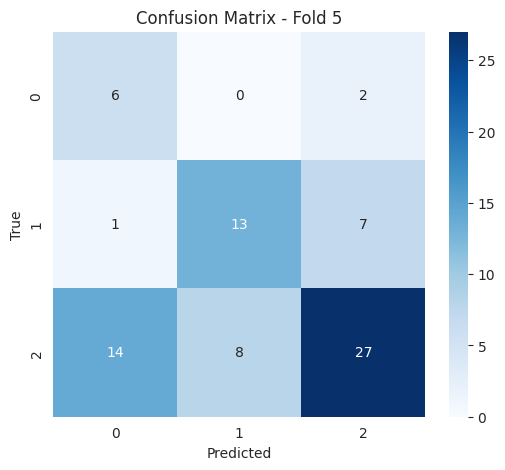

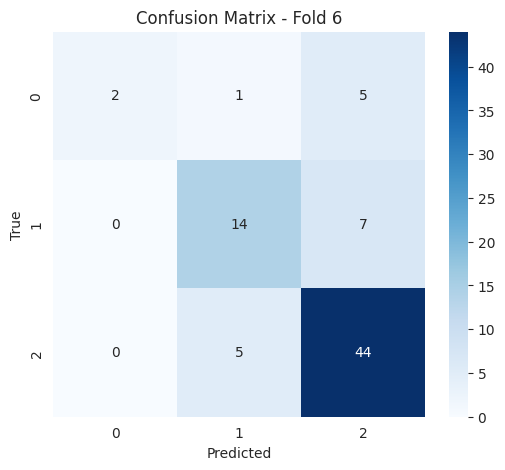

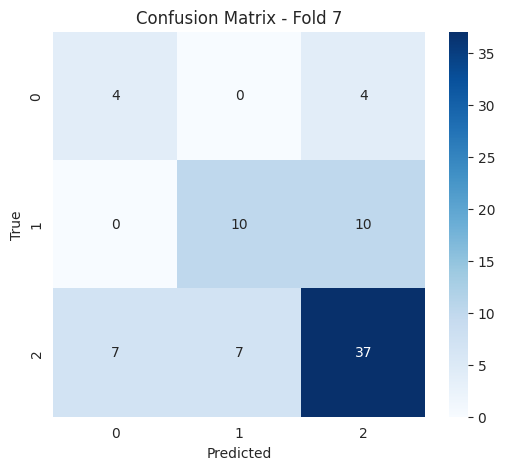

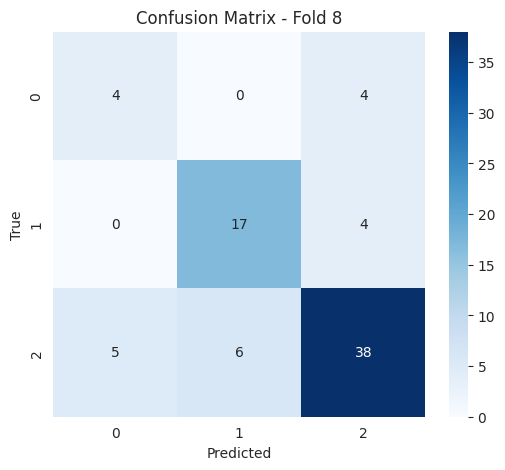

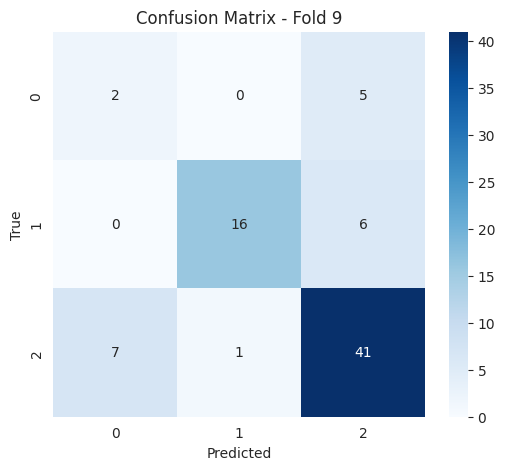

In [27]:
# Visualize Confusion Matrix for each fold
for i, cm in enumerate(confusion_matrices):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2], yticklabels=[0, 1, 2])
    plt.title(f'Confusion Matrix - Fold {i}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

Notes: These performance metrics are currently estimated on a slide-level and not patient-level. TO DO: Also have code for patient-level.